# Notebook 5 – CNN Image Classification



In [3]:
import time
import numpy as np
import torch
from torch import nn
torch.manual_seed(42)
np.random.seed(42)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('PyTorch:', torch.__version__, '| device:', device)

PyTorch: 2.14.0+cpu | device: cpu


## Concept and data inspection
Use training data to update weights, validation to select settings, and test once for final evaluation. Inspect samples and class counts before fitting. Fashion-MNIST is 1-channel; CIFAR-10 is 3-channel and more challenging because of color, backgrounds, and object variation. Use an unaugmented deterministic transform for validation/test.

batch: torch.Size([64, 1, 28, 28]) batch counts: tensor([ 3,  9,  7, 10,  4,  7,  7,  4,  6,  7])
training subset class counts: [457 556 504 501 488 493 493 512 490 506]


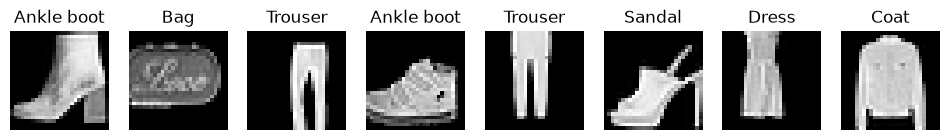

In [4]:
from torchvision import datasets,transforms
from torch.utils.data import DataLoader,Subset
import matplotlib.pyplot as plt
classes=['T-shirt/top','Trouser','Pullover','Dress','Coat','Sandal','Shirt','Sneaker','Bag','Ankle boot']
train_tf=transforms.Compose([transforms.RandomCrop(28,padding=3),transforms.ToTensor(),transforms.Normalize((.2860,),(.3530,))])
eval_tf=transforms.Compose([transforms.ToTensor(),transforms.Normalize((.2860,),(.3530,))])
train_ds=datasets.FashionMNIST('data',train=True,download=True,transform=train_tf); train_eval=datasets.FashionMNIST('data',train=True,download=False,transform=eval_tf); test_ds=datasets.FashionMNIST('data',train=False,download=True,transform=eval_tf)
train_loader=DataLoader(Subset(train_ds,range(5000)),batch_size=64,shuffle=True); val_loader=DataLoader(Subset(train_eval,range(5000,6000)),batch_size=128); test_loader=DataLoader(Subset(test_ds,range(1000)),batch_size=128)
xb,yb=next(iter(train_loader)); print('batch:',xb.shape,'batch counts:',torch.bincount(yb,minlength=10))
print('training subset class counts:',np.bincount(np.asarray(train_ds.targets[:5000]),minlength=10))
fig,axes=plt.subplots(1,8,figsize=(12,2))
for ax,img,label in zip(axes,xb[:8],yb[:8]): ax.imshow(img.squeeze(),cmap='gray'); ax.set_title(classes[label]); ax.axis('off')
plt.show()

In [5]:
class FashionCNN(nn.Module):
 def __init__(self,in_channels=1,n_classes=10):
  super().__init__(); self.features=nn.Sequential(nn.Conv2d(in_channels,32,3,padding=1),nn.BatchNorm2d(32),nn.ReLU(),nn.MaxPool2d(2),nn.Conv2d(32,64,3,padding=1),nn.ReLU(),nn.MaxPool2d(2),nn.AdaptiveAvgPool2d((3,3))); self.head=nn.Sequential(nn.Flatten(),nn.Dropout(.25),nn.Linear(64*9,n_classes))
 def forward(self,x): return self.head(self.features(x))
model=FashionCNN().to(device); opt=torch.optim.Adam(model.parameters(),lr=1e-3)
def evaluate(loader,collect=False):
 model.eval(); good=total=0; pp=[]; yy=[]
 with torch.no_grad():
  for xb,y in loader:
   pred=model(xb.to(device)).argmax(1).cpu(); good+=(pred==y).sum().item(); total+=len(y); pp.extend(pred.tolist()); yy.extend(y.tolist())
 return good/total,np.array(pp),np.array(yy)
for epoch in range(2):
 model.train(); loss_sum=count=0
 for xb,y in train_loader:
  xb,y=xb.to(device),y.to(device); opt.zero_grad(); loss=nn.functional.cross_entropy(model(xb),y); loss.backward(); opt.step(); loss_sum+=loss.item()*len(y); count+=len(y)
 print('epoch',epoch+1,'loss',round(loss_sum/count,3),'val_acc',round(evaluate(val_loader)[0],3))
test_acc,pred,true=evaluate(test_loader,True); print('test accuracy:',round(test_acc,3))

epoch 1 loss 1.437 val_acc 0.684
epoch 2 loss 0.905 val_acc 0.725
test accuracy: 0.73


## Test errors and CIFAR-10 extension
After selecting the model on validation, inspect a confusion matrix and both correct and incorrect images. For CIFAR-10, load `datasets.CIFAR10`, use 3-channel normalization, set `in_channels=3`, and choose label-preserving crop/flip augmentation. Do not repeatedly tune against the test set.

For each major error, answer: **What went wrong? Why might it have happened? How could it be improved?** Support the explanation with examples or subgroup metrics.

most confused true→predicted pairs:
[('Pullover', 'Coat', np.int64(34)), ('Shirt', 'Coat', np.int64(30)), ('Coat', 'Pullover', np.int64(25)), ('Shirt', 'Pullover', np.int64(24)), ('Shirt', 'T-shirt/top', np.int64(17))]


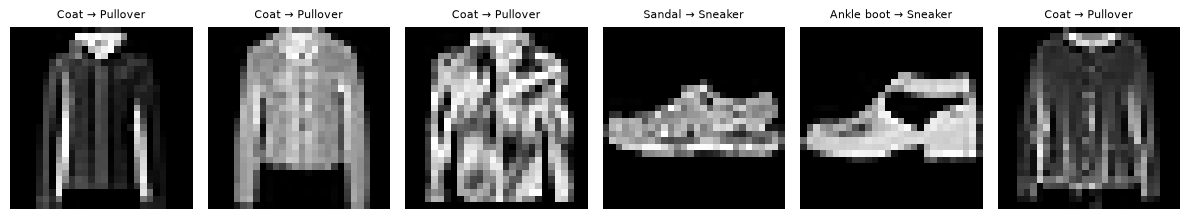

In [6]:
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
cm=confusion_matrix(true,pred); print('most confused true→predicted pairs:')
pairs=sorted([(cm[i,j],i,j) for i in range(10) for j in range(10) if i!=j],reverse=True)[:5]
print([(classes[i],classes[j],count) for count,i,j in pairs])
fig,axes=plt.subplots(1,6,figsize=(12,2.5))
for ax,index in zip(axes,np.flatnonzero(pred!=true)[:6]):
 image,label=test_ds[index]
 ax.imshow(image.squeeze(),cmap='gray'); ax.set_title(f'{classes[true[index]]} → {classes[pred[index]]}',fontsize=8); ax.axis('off')
plt.tight_layout(); plt.show()


## Optional CIFAR-10 challenge
The same workflow can handle RGB input by changing to three input channels, using RGB statistics, and keeping the validation/test transforms deterministic. The cell below is opt-in because it downloads CIFAR-10.


In [7]:
RUN_CIFAR10=False
if RUN_CIFAR10:
    cifar_train_tf=transforms.Compose([transforms.RandomCrop(32,padding=4),transforms.RandomHorizontalFlip(),transforms.ToTensor(),transforms.Normalize((.4914,.4822,.4465),(.247,.243,.261))])
    cifar_eval_tf=transforms.Compose([transforms.ToTensor(),transforms.Normalize((.4914,.4822,.4465),(.247,.243,.261))])
    cifar_train=datasets.CIFAR10('data',train=True,download=True,transform=cifar_train_tf)
    cifar_eval=datasets.CIFAR10('data',train=True,download=False,transform=cifar_eval_tf)
    cifar_test=datasets.CIFAR10('data',train=False,download=True,transform=cifar_eval_tf)
    train_loader=DataLoader(Subset(cifar_train,range(3000)),batch_size=64,shuffle=True)
    val_loader=DataLoader(Subset(cifar_eval,range(3000,3500)),batch_size=128)
    test_loader=DataLoader(Subset(cifar_test,range(500)),batch_size=128)
    model=FashionCNN(in_channels=3,n_classes=10).to(device); optimizer=torch.optim.Adam(model.parameters(),lr=1e-3)
    for epoch in range(2):
        model.train()
        for xb,yb in train_loader:
            xb,yb=xb.to(device),yb.to(device); optimizer.zero_grad(); loss=nn.functional.cross_entropy(model(xb),yb); loss.backward(); optimizer.step()
        print('CIFAR epoch',epoch+1,'validation accuracy',round(evaluate(val_loader)[0],3))
    print('CIFAR test accuracy',round(evaluate(test_loader)[0],3))
else:
    print('Set RUN_CIFAR10=True to download and run the optional RGB experiment.')


Set RUN_CIFAR10=True to download and run the optional RGB experiment.
